# Tutorial 4: Mesh Operations

Before a mesh reaches a model, a pipeline usually changes it. It rotates the
mesh for data augmentation, refines it, crops it, combines parts, extracts a
surface, or moves fields between points and cells. This tutorial shows the
`Mesh` method for each step, and how each one carries the attached data along.

**What You Will Build**: a smooth surface subdivided from a coarse cage, plus
rotated, sliced, merged, and boundary meshes that keep their fields.

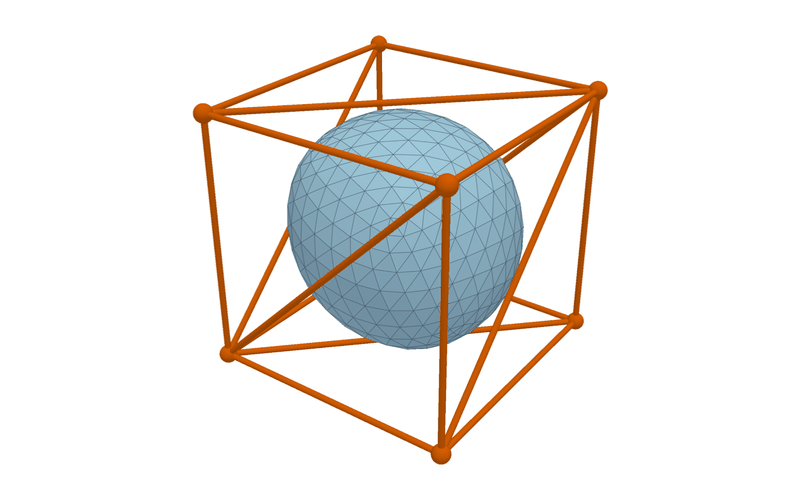

In [1]:
from IPython.display import Image

Image(filename="../../../docs/img/mesh/thumbnails/subdivision.png", width=400)

You will learn:

- How to transform a mesh, and its vector fields, with `translate`, `scale`,
  `rotate`, and `transform`.
- How to refine a mesh with `subdivide`, and select or combine meshes with
  `slice_cells`, `slice_points`, and `Mesh.merge`.
- How to extract boundaries, facets, and edge graphs, and convert fields
  between points and cells.

Prerequisites: [Tutorial 1](tutorial_1_getting_started.ipynb) (the `Mesh` data
model), [Tutorial 2](tutorial_2_io_interop.ipynb), and
[Tutorial 3](tutorial_3_primitives_generation.ipynb) (the primitives used
here). The examples run on a CPU in a few seconds. Every operation also runs
on a GPU, on a mesh that you move there with `mesh.to("cuda")`.

In [2]:
import math

import pyvista as pv
import torch

from physicsnemo.mesh import Mesh
from physicsnemo.mesh.primitives.surfaces import sphere_icosahedral
from physicsnemo.mesh.primitives.volumes import cube_volume

pv.set_jupyter_backend("static")
pv.global_theme.window_size = [600, 400]
torch.set_printoptions(precision=3, sci_mode=False)

Several figures in this tutorial compare meshes side by side. This helper
draws each mesh into one panel of a PyVista plotter with `Mesh.draw`.

In [3]:
def show_row(meshes, titles, **draw_kwargs):
    """Draw meshes side by side, with linked cameras."""
    plotter = pv.Plotter(shape=(1, len(meshes)), window_size=[300 * len(meshes), 300])
    for i, (mesh, title) in enumerate(zip(meshes, titles)):
        plotter.subplot(0, i)
        mesh.draw(ax=plotter, show=False, **draw_kwargs)
        plotter.add_text(title, position=(0.03, 0.9), viewport=True, font_size=12)
    plotter.link_views()
    plotter.show()

## 1. Geometric Transformations

Rotations, reflections, and scalings are the standard augmentations for
models of physical systems, because the physics does not depend on how the
object is placed. Each transformation returns a new mesh and leaves the
original unchanged.

`translate` adds an offset, and `scale` multiplies by a factor, either one
factor for all axes or one for each axis.

In [4]:
sphere = sphere_icosahedral.load(subdivisions=2)


def extent(mesh):
    """Size of the axis-aligned bounding box."""
    return mesh.points.max(dim=0).values - mesh.points.min(dim=0).values


moved = sphere.translate([5.0, 0.0, 0.0])
print(f"Center before: {sphere.points.mean(dim=0)}")
print(f"Center after translate: {moved.points.mean(dim=0)}")
print(f"Extent before: {extent(sphere)}")
print(f"Extent after scale(2.0): {extent(sphere.scale(2.0))}")
print(f"Extent after scale([2.0, 1.0, 0.5]): {extent(sphere.scale([2.0, 1.0, 0.5]))}")

Center before: tensor([ 0.000, -0.000, -0.000])
Center after translate: tensor([ 5.000, -0.000, -0.000])
Extent before: tensor([2., 2., 2.])
Extent after scale(2.0): tensor([4., 4., 4.])
Extent after scale([2.0, 1.0, 0.5]): tensor([4., 2., 1.])


`rotate` takes an angle in radians and, in 3D, an axis: a vector, or one of
`"x"`, `"y"`, `"z"`. In 2D, it takes no axis. `transform` applies any matrix,
which covers shears and the other linear maps. The figure shows the Stanford
bunny (from `assets/`) after three of these operations.

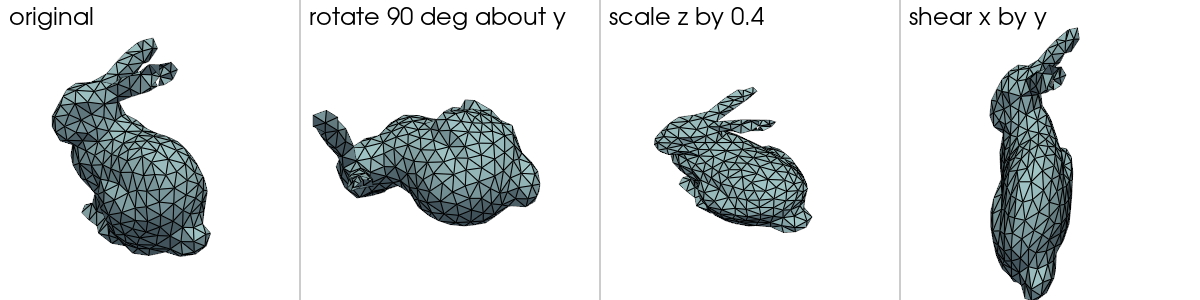

In [5]:
bunny = torch.load("assets/bunny.pt", weights_only=False)

shear = torch.tensor(
    [
        [1.0, 0.8, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0],
    ]
)
show_row(
    [
        bunny,
        bunny.rotate(angle=math.pi / 2, axis="y"),
        bunny.scale([1.0, 1.0, 0.4]),
        bunny.transform(shear),
    ],
    ["original", "rotate 90 deg about y", "scale z by 0.4", "shear x by y"],
    alpha_points=0.0,
)

`rotate` supports 2D and 3D meshes only. In four or more dimensions, an angle
and an axis do not define a unique rotation. Build the rotation matrix and
pass it to `transform`.

### Transform Fields with the Geometry

A mesh for ML usually carries fields, for example a velocity at each point. A
scalar such as pressure does not change when you rotate the mesh, but a vector
must rotate with it. By default, the transformations move only the geometry.
Set `transform_point_data=True` (or `transform_cell_data`,
`transform_global_data`) to transform the fields too.

In [6]:
sphere = sphere_icosahedral.load(subdivisions=2)
sphere.point_data["velocity"] = torch.tensor([1.0, 0.0, 0.0]).repeat(sphere.n_points, 1)
sphere.point_data["pressure"] = sphere.points[:, 2].clone()

geometry_only = sphere.rotate(angle=math.pi / 2, axis="z")
with_fields = sphere.rotate(angle=math.pi / 2, axis="z", transform_point_data=True)

print(f"velocity, geometry only: {geometry_only.point_data['velocity'][0]}")
print(f"velocity, with fields:   {with_fields.point_data['velocity'][0]}")
print(
    "pressure unchanged:",
    torch.equal(with_fields.point_data["pressure"], sphere.point_data["pressure"]),
)

velocity, geometry only: tensor([1., 0., 0.])
velocity, with fields:   tensor([-0.000,  1.000,  0.000])
pressure unchanged: True


After a 90-degree rotation about z, the velocity (1, 0, 0) becomes (0, 1, 0)
when the fields rotate with the geometry. With the default, the velocity keeps
its old direction and no longer matches the rotated mesh.

The rule follows from the shape of each field:

- A field with no trailing dimensions is a scalar and does not change.
- A field of shape `(n_points, n_spatial_dims)` is a vector `v` and becomes
  `M v`.
- A field of shape `(n_points, n_spatial_dims, n_spatial_dims)` is a rank-2
  tensor `T` and becomes `M T Mᵀ`.
- With `transform_point_data=True`, a field of any other shape, such as
  `(n_points, 5)`, raises a `ValueError`.

To transform only some fields, pass a dictionary, for example
`transform_point_data={"velocity": True}`.
[Tutorial 9](tutorial_9_ml_integration.ipynb) shows how a model declares the
rank of each field it reads.

### Change the Spatial Dimension

The matrix given to `transform` does not have to be square. A 2x3 matrix maps
3D points to 2D, so the result is a surface mesh in 2D space. Here, the
matrix drops the z coordinate. The color shows the z coordinate of each point
before the projection.

Spatial dimensions: 3 -> 2
Manifold dimensions: 2 -> 2


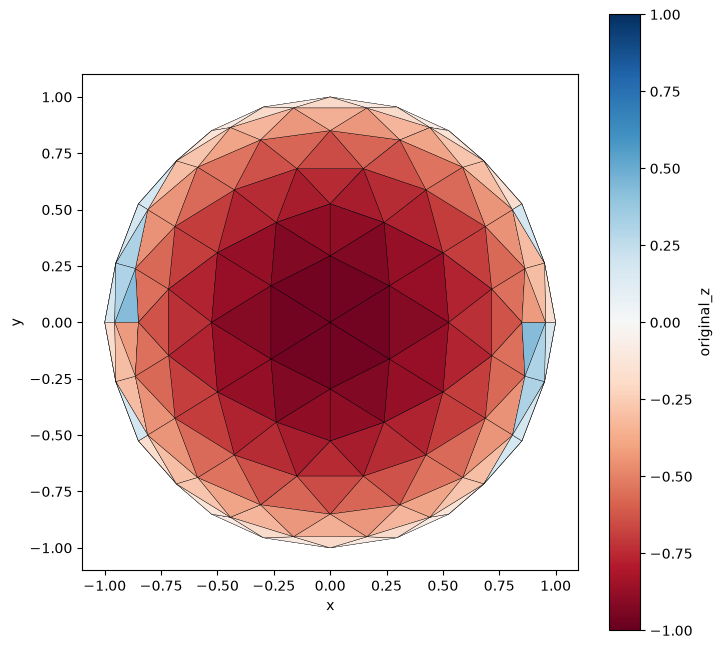

In [7]:
sphere = sphere_icosahedral.load(subdivisions=2)
sphere.point_data["original_z"] = sphere.points[:, 2]

drop_z = torch.tensor(
    [
        [1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
    ]
)
projected = sphere.transform(drop_z)
print(f"Spatial dimensions: {sphere.n_spatial_dims} -> {projected.n_spatial_dims}")
print(f"Manifold dimensions: {sphere.n_manifold_dims} -> {projected.n_manifold_dims}")
_ = projected.draw(point_scalars="original_z", cmap="RdBu")

Both halves of the sphere land on the same disk, so the disk is covered
twice. The plot draws the half with z < 0 (red) over the half with z > 0
(blue), which shows only near the rim. The projected mesh still has its 320
triangles, but it is no longer a valid surface. It folds over itself at the
rim.

## 2. Subdivision

Subdivision splits every cell into smaller cells. Use it to increase the
resolution of a coarse mesh, or to make a smooth surface from a coarse control
mesh. The `filter` argument selects where the new points go:

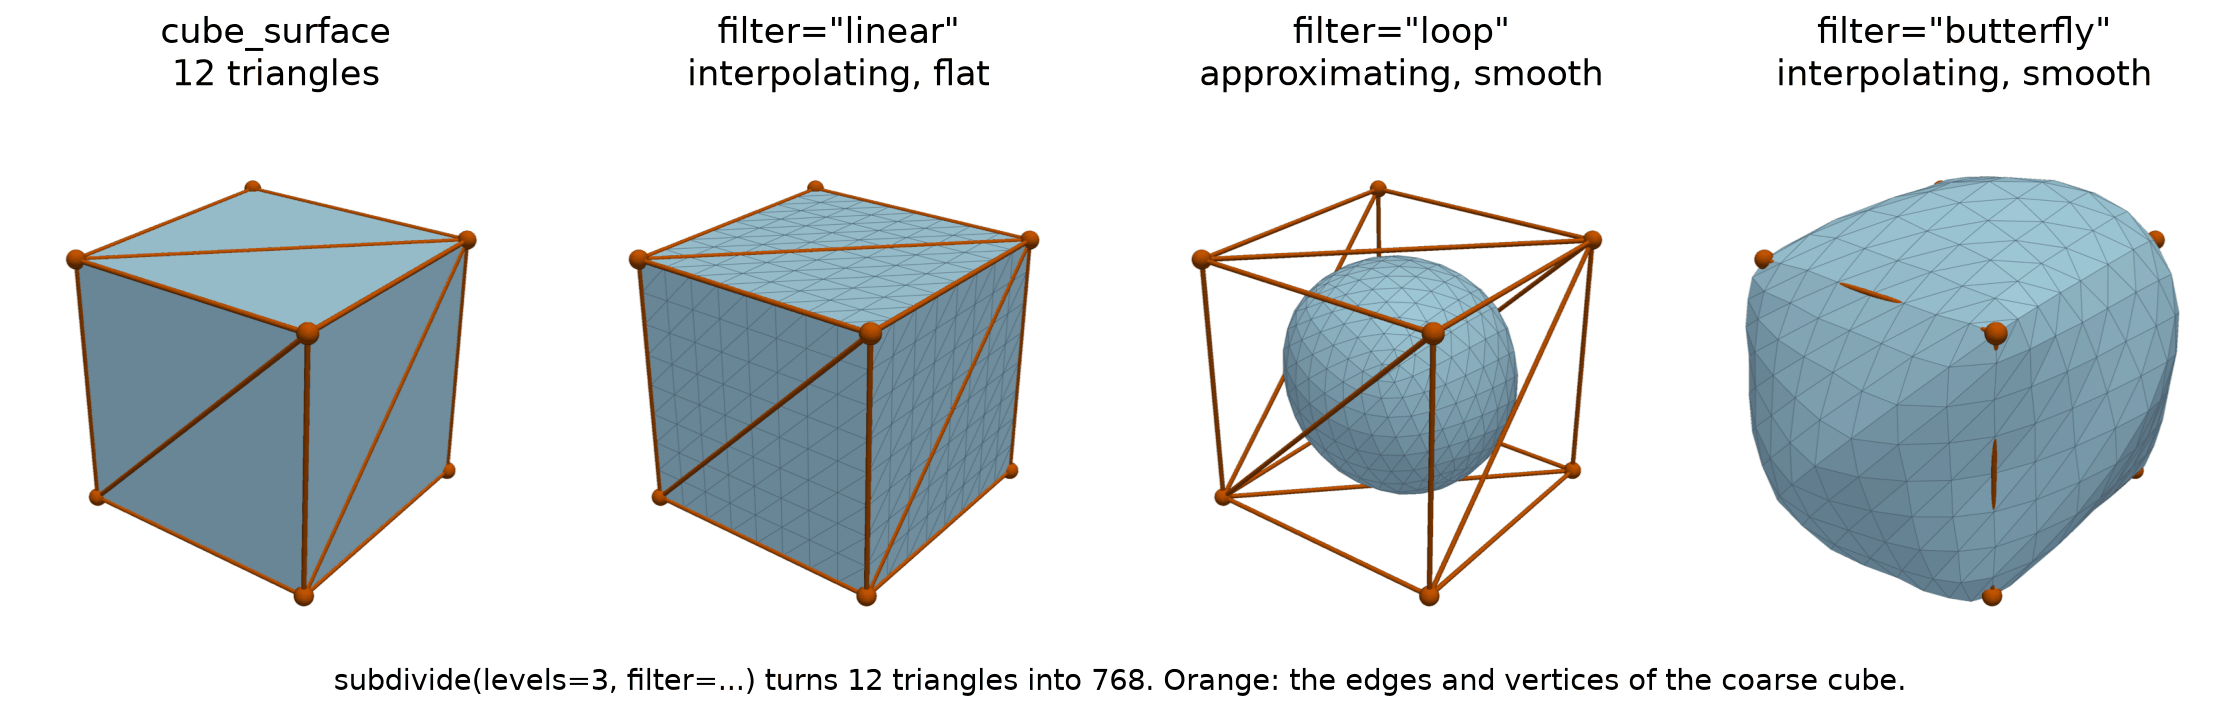

In [8]:
Image(filename="../../../docs/img/mesh/subdivision_schemes.png", width=900)

Each level splits an n-dimensional simplex into 2ⁿ children, so a triangle
mesh gets four times as many cells for each level:

In [9]:
coarse = sphere_icosahedral.load(subdivisions=0)
for levels in range(4):
    refined = coarse.subdivide(levels=levels, filter="linear")
    print(f"{levels} levels: {refined.n_points:5d} points, {refined.n_cells:5d} cells")

0 levels:    12 points,    20 cells
1 levels:    42 points,    80 cells
2 levels:   162 points,   320 cells
3 levels:   642 points,  1280 cells


The three schemes differ in where they put the points:

| `filter` | New Points | Original Points | Manifold Dimensions |
|---|---|---|---|
| `"linear"` | Edge midpoints | Kept | Any |
| `"butterfly"` | Weighted stencil of neighbors | Kept (interpolating) | 2 only |
| `"loop"` | Weighted stencil of neighbors | Moved (approximating) | 2 only |

On a convex mesh such as an icosahedron, Loop shrinks the surface toward the
inside, because it moves the original points too. The radii show it:

linear   : radius from 0.809 to 1.000
butterfly: radius from 0.975 to 1.000
loop     : radius from 0.716 to 0.721


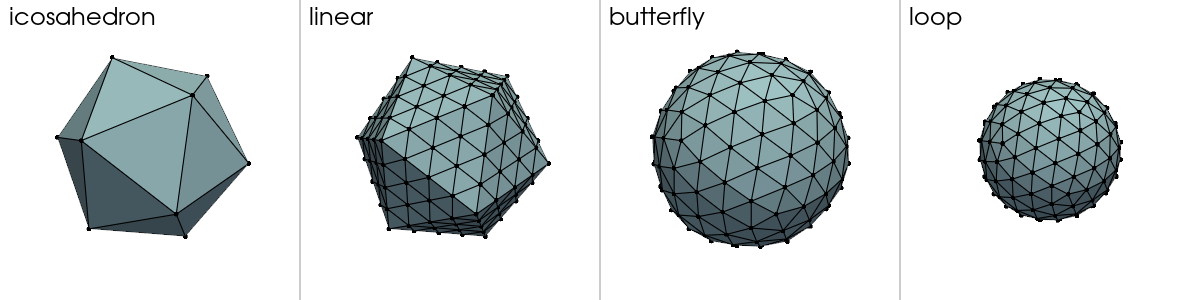

In [10]:
schemes = ["linear", "butterfly", "loop"]
subdivided = [coarse.subdivide(levels=2, filter=s) for s in schemes]
for scheme, mesh in zip(schemes, subdivided):
    radius = mesh.points.norm(dim=-1)
    print(f"{scheme:9s}: radius from {radius.min():.3f} to {radius.max():.3f}")
show_row([coarse] + subdivided, ["icosahedron"] + schemes)

Linear and Butterfly keep the 12 original points on the unit sphere, and
Butterfly places the new points much closer to it. Loop moves every point
inward, to a radius of about 0.72.

Subdivision carries the data along. Each new point gets the mean of the point
data at the two ends of its edge, and each child cell inherits the cell data
of its parent. The original points keep their values even when Loop moves
them, so after Loop subdivision the height no longer equals z. The parent
cells here get their numbers in random order, so that neighboring patches
usually get different colors:

Points: 42 -> 642
Cells: 80 -> 1280
point_data keys: ['height']
cell_data keys: ['cell_id']
Largest difference between height and z: 0.083


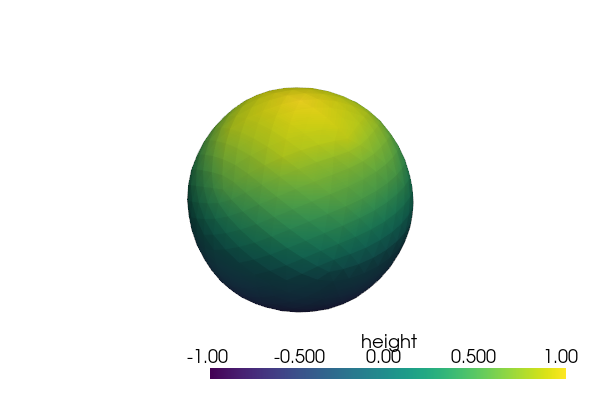

In [11]:
mesh = sphere_icosahedral.load(subdivisions=1)
mesh.point_data["height"] = mesh.points[:, 2]
shuffle = torch.Generator().manual_seed(0)
mesh.cell_data["cell_id"] = torch.randperm(mesh.n_cells, generator=shuffle).float()

refined = mesh.subdivide(levels=2, filter="loop")
print(f"Points: {mesh.n_points} -> {refined.n_points}")
print(f"Cells: {mesh.n_cells} -> {refined.n_cells}")
print(f"point_data keys: {list(refined.point_data.keys())}")
print(f"cell_data keys: {list(refined.cell_data.keys())}")
height_error = (refined.point_data["height"] - refined.points[:, 2]).abs().max()
print(f"Largest difference between height and z: {height_error:.3f}")
_ = refined.draw(point_scalars="height", alpha_points=0.0, show_edges=False)

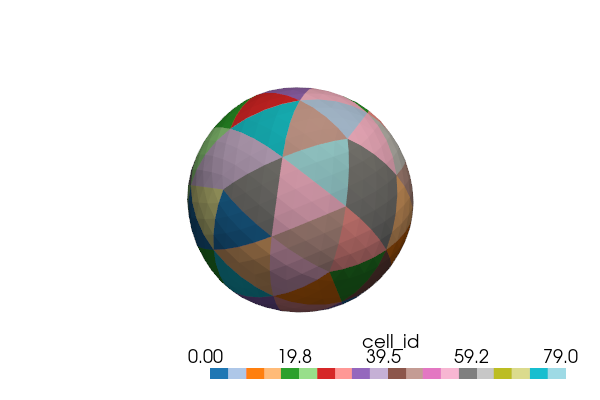

In [12]:
_ = refined.draw(
    cell_scalars="cell_id", cmap="tab20", show_edges=False, alpha_points=0.0
)

Each of the 80 parent cells became 16 child cells with the same `cell_id`, so
the color is constant over each patch of 16 triangles.

## 3. Slicing

Slicing keeps a subset of a mesh, for example the cells in a region of
interest. Pass an integer index tensor or a boolean mask. There are two
methods, and they treat the cells on the cut differently.

`slice_cells` keeps the selected cells. It keeps every point, including the
points that no remaining cell uses. `clean()` removes those points and
renumbers the cells.

In [13]:
sphere = sphere_icosahedral.load(subdivisions=2)
by_cells = sphere.slice_cells(sphere.cell_centroids[:, 2] > 0)
print(f"Original: {sphere.n_points} points, {sphere.n_cells} cells")
print(f"slice_cells: {by_cells.n_points} points, {by_cells.n_cells} cells")
print(f"after clean(): {by_cells.clean().n_points} points")

Original: 162 points, 320 cells
slice_cells: 162 points, 152 cells


after clean(): 89 points


`slice_points` keeps the selected points. It removes every cell that uses a
removed point, and renumbers the cells that remain.

slice_points: 73 points, 122 cells


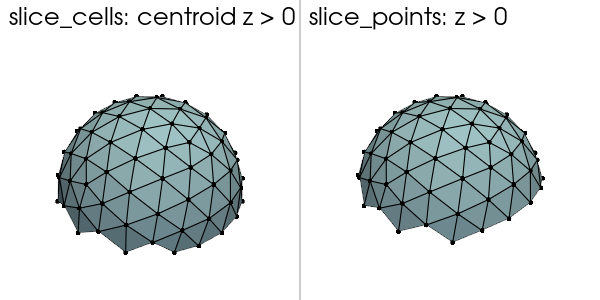

In [14]:
by_points = sphere.slice_points(sphere.points[:, 2] > 0)
print(f"slice_points: {by_points.n_points} points, {by_points.n_cells} cells")
show_row(
    [by_cells.clean(), by_points],
    ["slice_cells: centroid z > 0", "slice_points: z > 0"],
)

`slice_cells` keeps 152 cells: every cell whose centroid is above the equator.
`slice_points` keeps 122 cells, because it also drops the cells that have one
point on or below the equator.

The result of `slice_cells` shares `points`, `point_data`, and `global_data`
with the original mesh. If you modify those tensors in place, clone the mesh
first. `slice_points` copies the selected points and their data into new
tensors, and shares only `global_data`. An index tensor works the same way as
a mask:

In [15]:
every_other = sphere.slice_cells(torch.arange(0, sphere.n_cells, 2))
print(f"Every other cell: {every_other.n_cells} cells")

Every other cell: 160 cells


## 4. Merging Meshes

`Mesh.merge` combines several meshes into one, for example the parts of an
assembly, or a batch of samples for a model that accepts one large mesh. The
merge renumbers the cells of each mesh so that they refer to its own points.

Each sphere: 162 points, 320 cells
Merged: 486 points, 960 cells


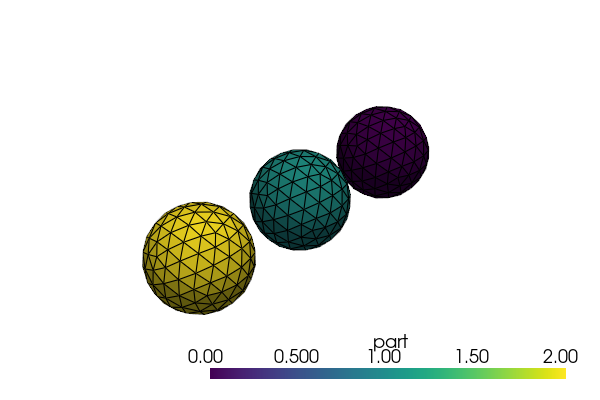

In [16]:
spheres = [
    sphere_icosahedral.load(subdivisions=2).translate([x, 0.0, 0.0])
    for x in (-2.5, 0.0, 2.5)
]
for i, s in enumerate(spheres):
    s.point_data["part"] = torch.full((s.n_points,), float(i))

merged = Mesh.merge(spheres)
print(f"Each sphere: {spheres[0].n_points} points, {spheres[0].n_cells} cells")
print(f"Merged: {merged.n_points} points, {merged.n_cells} cells")
_ = merged.draw(point_scalars="part", cmap="viridis", alpha_points=0.0)

The meshes must have the same spatial dimension, the same manifold dimension,
and the same keys in `point_data`, `cell_data`, and `global_data`. The manifold
dimension must match because the `cells` tensor has one width,
`n_manifold_dims + 1`, so one `Mesh` cannot hold both triangles and
tetrahedra.

A simulation domain often needs both: for example, a tetrahedral volume mesh
of the air around a car and the triangle mesh of the car surface. Keep them as
separate meshes, in a `DomainMesh` (refer to
[Tutorial 8](tutorial_8_domain_mesh.ipynb)).

## 5. Boundaries and Facets

Many models need the surface of a volume mesh, for example to apply boundary
conditions or to compute forces on a body. A facet of an n-dimensional cell is
one of its (n-1)-dimensional faces. `get_boundary_mesh()` returns the facets
that belong to exactly one cell, and `get_facet_mesh()` returns all facets.
The figure shows both on a planar mesh, and the boundary of a tetrahedral
volume:

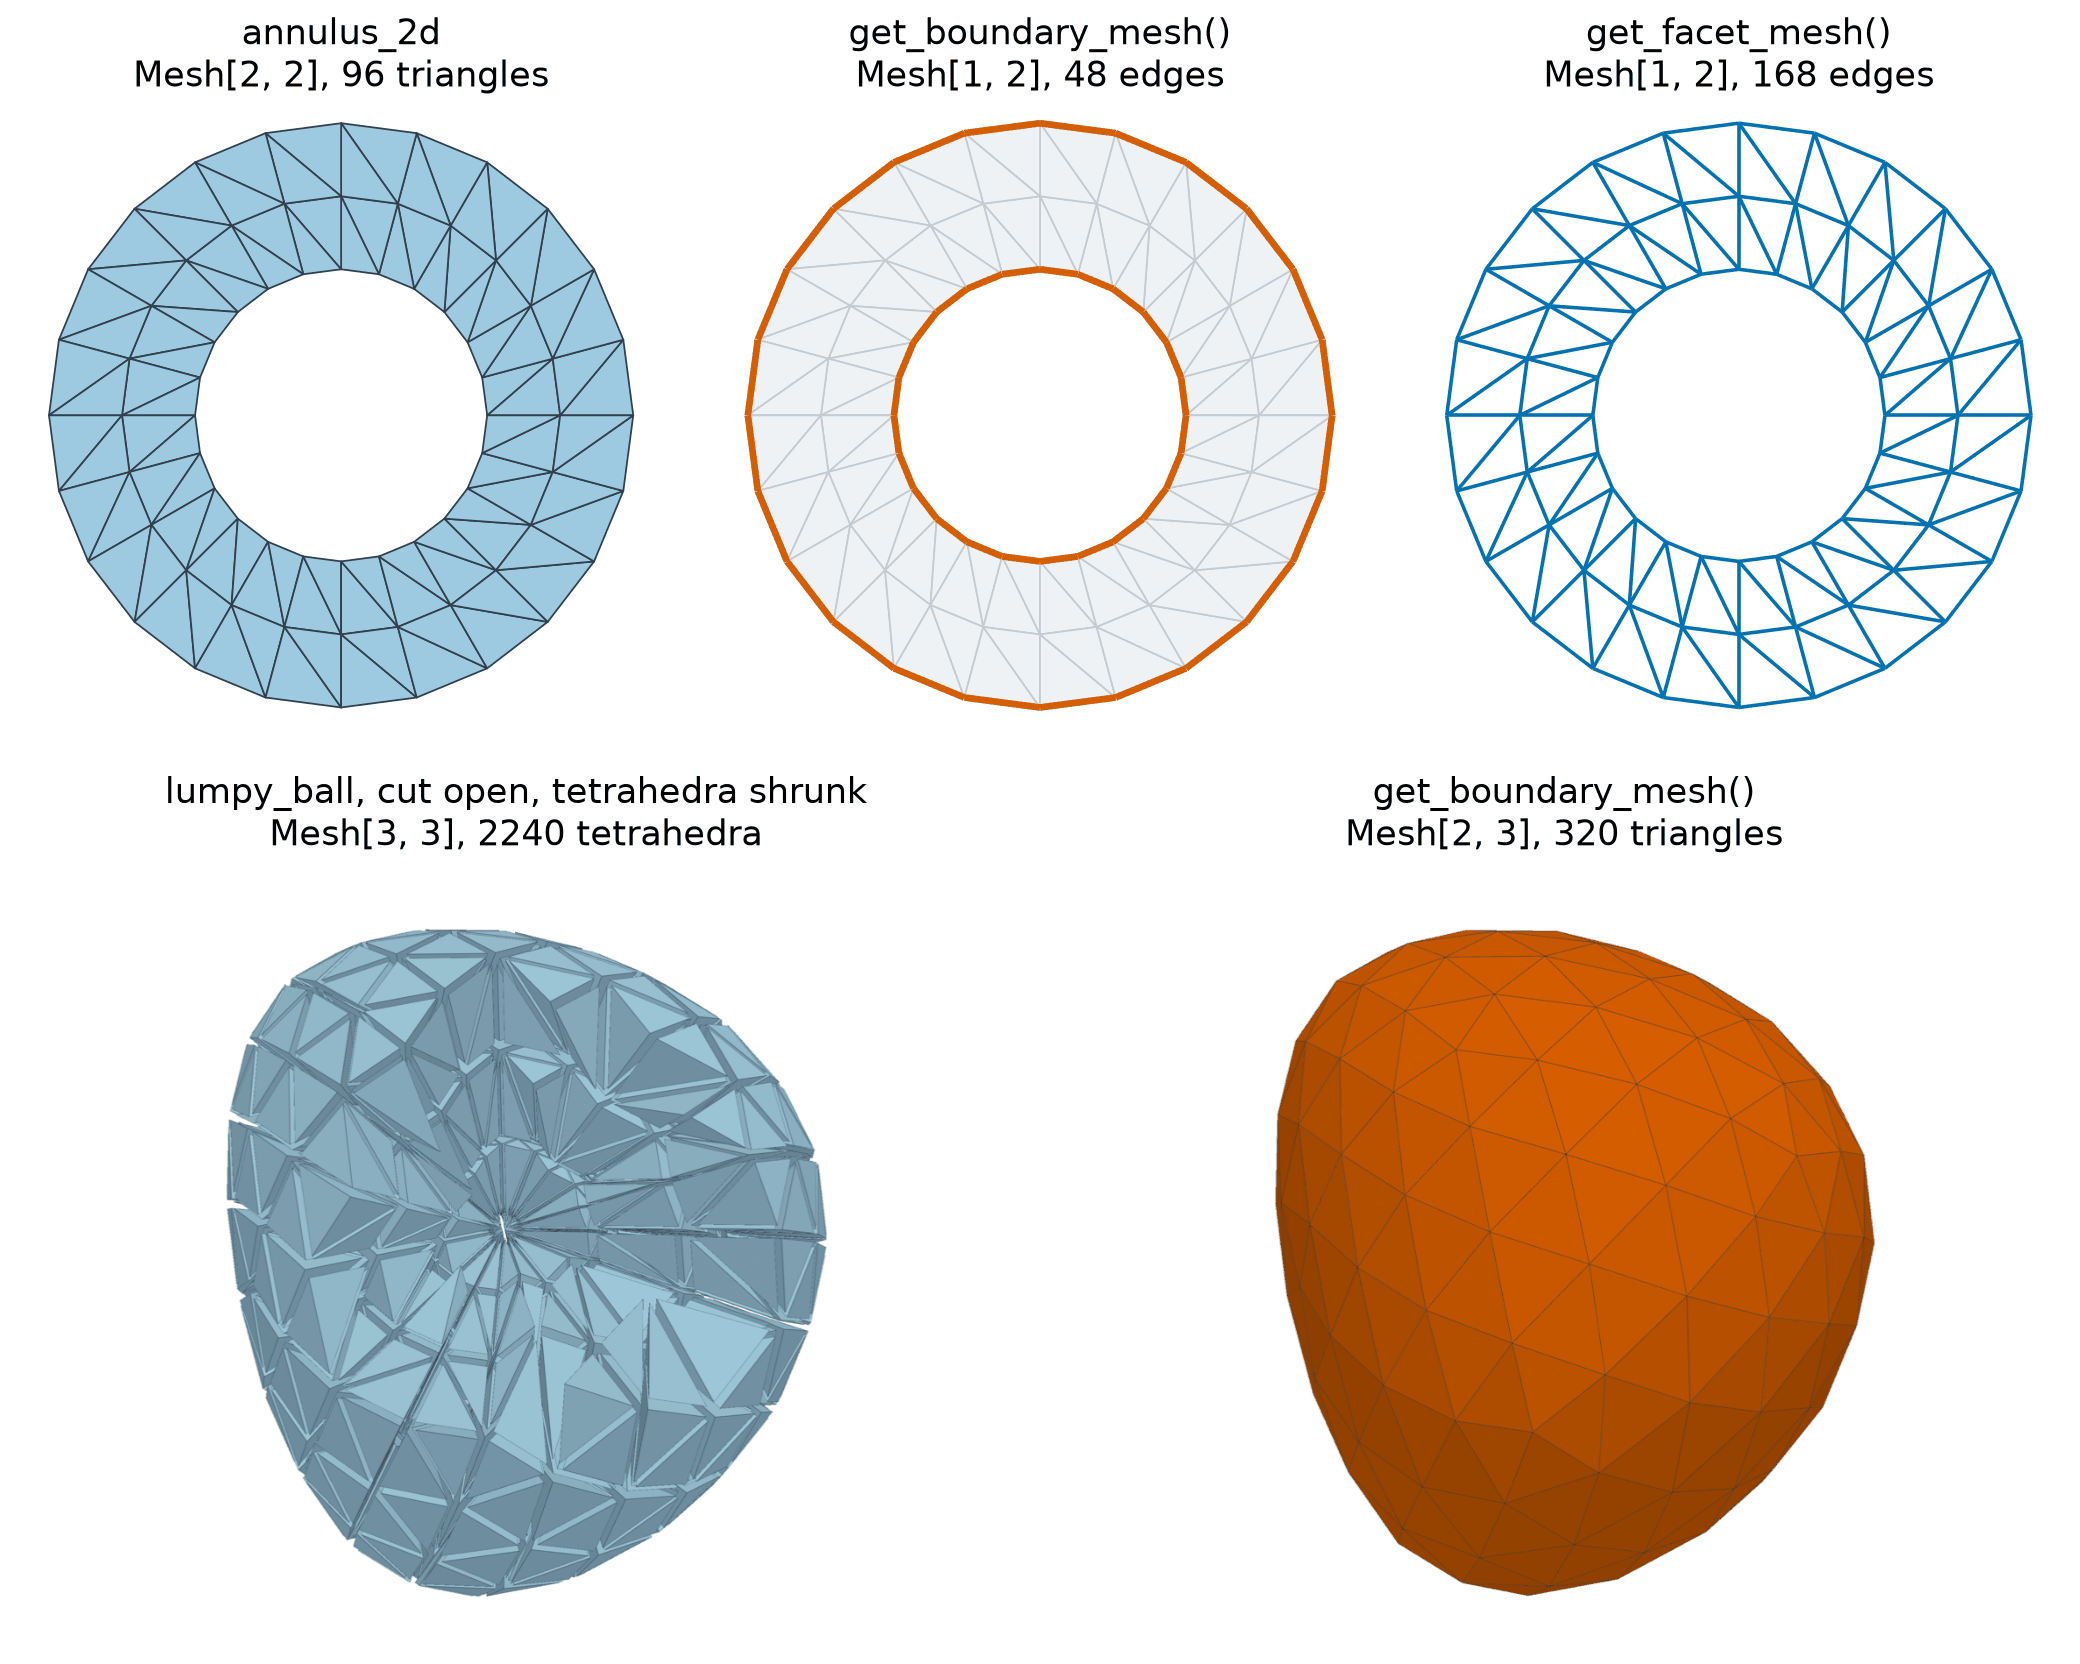

In [17]:
Image(filename="../../../docs/img/mesh/boundaries_facets.png", width=800)

The same calls work on a tetrahedral mesh of a cube. The boundary of the
volume is a triangle surface. It refers to the same point
tensor as the volume, so it still lists the 27 interior points. `clean()`
removes them. The boundary of a closed surface is empty.

In [18]:
cube = cube_volume.load(subdivisions=4)
print(f"Volume mesh: {cube}")
boundary = cube.get_boundary_mesh()
print(f"Boundary: {boundary}")
print(f"Boundary after clean(): {boundary.clean()}")
print(f"Cells in the boundary of the boundary: {boundary.get_boundary_mesh().n_cells}")

Volume mesh: Mesh[n_manifold_dims=3, n_spatial_dims=3](n_points=125, n_cells=384)
Boundary: Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=125, n_cells=192)


Boundary after clean(): Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=98, n_cells=192)
Cells in the boundary of the boundary: 0


`manifold_codimension` sets how many dimensions `get_facet_mesh` steps down,
so you can extract all edges of a volume mesh at once:

| Cells | `manifold_codimension` | Facets | Per Cell, Before Shared Facets Are Merged |
|---|---|---|---|
| Triangles | 1 | Edges | 3 |
| Triangles | 2 | Points | 3 |
| Tetrahedra | 1 | Triangles | 4 |
| Tetrahedra | 2 | Edges | 6 |

In [19]:
print(f"Triangles of the volume: {cube.get_facet_mesh(manifold_codimension=1)}")
print(f"Edges of the volume: {cube.get_facet_mesh(manifold_codimension=2)}")
edges = boundary.clean().get_facet_mesh(manifold_codimension=1)
print(f"Edges of the boundary: {edges}")

Triangles of the volume: Mesh[n_manifold_dims=2, n_spatial_dims=3](n_points=125, n_cells=864)
Edges of the volume: Mesh[n_manifold_dims=1, n_spatial_dims=3](n_points=125, n_cells=604)
Edges of the boundary: Mesh[n_manifold_dims=1, n_spatial_dims=3](n_points=98, n_cells=288)


### Every Mesh Has an Edge Graph

A mesh with one manifold dimension is a graph embedded in space. Its points
are the nodes, and its cells are the edges. `to_edge_graph()` returns this
graph for any mesh. It gives the same 604 edges as the facet mesh of
codimension 2 above. Graph neural networks, such as the MeshGraphNet family,
pass messages along these edges. Section 3 of
[Tutorial 6](tutorial_6_neighbors_spatial.ipynb), "Graphs Are Meshes", adds
edge features to this graph and passes messages on it.

In [20]:
graph = cube.to_edge_graph()
print(f"Edge graph: {graph}")
print(f"Is a Mesh[1, 3]: {isinstance(graph, Mesh[1, 3])}")

Edge graph: Mesh[n_manifold_dims=1, n_spatial_dims=3](n_points=125, n_cells=604)
Is a Mesh[1, 3]: True


## 6. Converting between Point Data and Cell Data

Simulation output comes at points (a finite-element solution) or at cells (a
finite-volume solution), and a model can expect the other one. Two methods
convert between them:

- `cell_data_to_point_data()` gives each point the mean of the cells that
  contain it.
- `point_data_to_cell_data()` gives each cell the mean of its points.

Both methods convert every field, keep the original fields, and raise an error
if a target key already exists, unless you pass `overwrite_keys=True`. Averaging
smooths the field, so a round trip does not return the original values.

In [21]:
torch.manual_seed(0)
mesh = sphere_icosahedral.load(subdivisions=2)
mesh.cell_data["noise"] = torch.randn(mesh.n_cells)

to_points = mesh.cell_data_to_point_data()
back_to_cells = to_points.with_data(cell_data={}).point_data_to_cell_data()
print(f"point_data keys: {list(to_points.point_data.keys())}")
print(f"Standard deviation, original cells: {mesh.cell_data['noise'].std():.3f}")
print(f"Standard deviation, at points:      {to_points.point_data['noise'].std():.3f}")
print(
    f"Standard deviation, back at cells:  {back_to_cells.cell_data['noise'].std():.3f}"
)

point_data keys: ['noise']
Standard deviation, original cells: 0.925
Standard deviation, at points:      0.382
Standard deviation, back at cells:  0.274


Here, `with_data(cell_data={})` clears the cell data first, because the round
trip writes the key `noise` back into `cell_data`. Use `with_data` in the same
way to convert only some fields. Give it only the fields to convert.

cell_data keys: ['temperature']


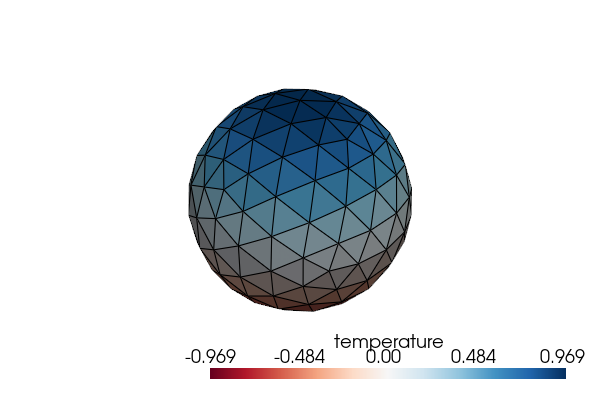

In [22]:
mesh = sphere_icosahedral.load(subdivisions=2)
mesh.point_data["temperature"] = mesh.points[:, 2]
mesh.point_data["velocity"] = torch.randn(mesh.n_points, 3)

only_temperature = mesh.with_data(point_data=mesh.point_data.select("temperature"))
converted = only_temperature.point_data_to_cell_data()
print(f"cell_data keys: {list(converted.cell_data.keys())}")
_ = converted.draw(cell_scalars="temperature", cmap="RdBu", alpha_points=0.0)

## Summary

This tutorial covered the following points:

- `translate`, `scale`, `rotate`, and `transform` return a new mesh. Pass
  `transform_point_data=True` (or a dictionary of field names) to transform
  vector and tensor fields with the geometry.
- `subdivide(levels, filter)` refines a mesh with the `"linear"`,
  `"butterfly"`, or `"loop"` scheme, and interpolates the data.
- `slice_cells` keeps cells, `slice_points` keeps points and drops the cells
  that use removed points, and `clean()` removes unused points.
- `Mesh.merge` combines meshes of the same dimensions with the same data keys.
- `get_boundary_mesh`, `get_facet_mesh`, and `to_edge_graph` extract
  lower-dimensional meshes. The edge graph of any mesh is a `Mesh[1, n]`.
- `cell_data_to_point_data` and `point_data_to_cell_data` move fields between
  cells and points by averaging.

## Next Steps

Continue with the following resources:

- **Next**: [Tutorial 5: Discrete Calculus and Curvature](tutorial_5_calculus.ipynb)
  computes gradients, divergence, curl, and curvature on meshes, measures
  their accuracy, and backpropagates a physics loss through them.
- API Reference:
  [transformations](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/transformations.html),
  [subdivision](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/subdivision.html),
  [boundaries](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/boundaries.html),
  and [core](https://docs.nvidia.com/physicsnemo/latest/physicsnemo/api/mesh/core.html)
  (`Mesh`, with slicing, merging, and data conversion).
- User Guide: [Using Meshes](https://docs.nvidia.com/physicsnemo/latest/user-guide/mesh/using_mesh.html).